# Exploration: churn drivers

Goal: understand which customers leave the operator before building a prediction model.

Data: `marts.customer_features` table built by dbt (7,043 customers, one row per customer).

## Loading the data

Read the feature table from DuckDB in read-only mode. The connection is closed right away
so it doesn't block `dbt build`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "warehouse" / "churn.duckdb"

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    df = con.execute("select * from marts.customer_features").df()

df.shape

(7043, 23)

In [11]:
df.dtypes #checking the column types

customer_id                   str
gender                        str
is_senior_citizen            bool
has_partner                  bool
has_dependents               bool
tenure_months               int32
contract_type                 str
has_paperless_billing        bool
payment_method                str
internet_service              str
has_phone_service            bool
has_multiple_lines           bool
has_online_security          bool
has_online_backup            bool
has_device_protection        bool
has_tech_support             bool
has_streaming_tv             bool
has_streaming_movies         bool
has_internet                 bool
nb_services                 int32
monthly_charges           float64
total_charges             float64
is_churned                   bool
tenure_bucket            category
dtype: object

In [ ]:
#What percentage of customers churned
df["is_churned"].value_counts(normalize=True)

is_churned
False    0.73463
True     0.26537
Name: proportion, dtype: float64

About 26.5% of customers churned: the classes are imbalanced. A model that always predicts
"stays" would reach 73.5% accuracy. Models will therefore be evaluated with ROC-AUC,
precision and recall rather than accuracy.

In [ ]:
#Churn Rate by Category (Contract_type, Internet services, payment method, nb services)
def churn_rate(col):
    return (
        df.groupby(col)["is_churned"]
        .agg(taux_churn="mean", nb_clients="size")
        .sort_values("taux_churn", ascending=False)
    )

churn_rate("contract_type")

,taux_churn,nb_clients
contract_type,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


In [5]:
churn_rate("internet_service")

,taux_churn,nb_clients
internet_service,,
Fiber optic,0.418928,3096
DSL,0.189591,2421
No,0.074050,1526


In [6]:
churn_rate("payment_method")

,taux_churn,nb_clients
payment_method,,
Electronic check,0.452854,2365
Mailed check,0.191067,1612
Bank transfer (automatic),0.167098,1544
Credit card (automatic),0.152431,1522


In [7]:
churn_rate("nb_services").sort_index()

,taux_churn,nb_clients
nb_services,,
0,0.437500,80
1,0.211052,1701
2,0.328283,1188
3,0.364767,965
4,0.313449,922
5,0.255507,908
6,0.224852,676
7,0.124051,395
8,0.052885,208


## Tenure

When in the customer relationship do departures concentrate?

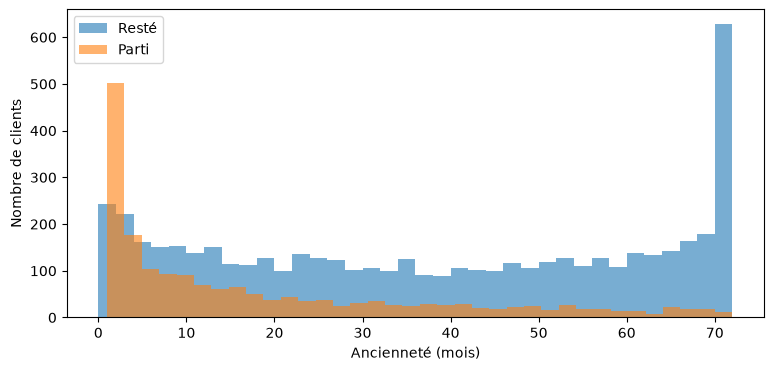

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.loc[~df["is_churned"], "tenure_months"], bins=36, alpha=0.6, label="Resté")
ax.hist(df.loc[df["is_churned"], "tenure_months"], bins=36, alpha=0.6, label="Parti")
ax.set_xlabel("Ancienneté (mois)")
ax.set_ylabel("Nombre de clients")
ax.legend()
plt.show()

The tenure distribution of churned customers is right-skewed: departures concentrate in the first
months (about 53% churn between 0 and 6 months, under 10% after 4 years). Retained customers show
a U-shaped distribution, with a peak of loyal customers around 70-72 months.

Business takeaway: the first months are the critical period for retention.
Modeling takeaway: `tenure_months` should be the most important feature. Note that `total_charges`
is roughly `tenure_months × monthly_charges`, so these three features are strongly correlated.

In [9]:
df.pivot_table(
    index="nb_services",
    columns="has_internet",
    values="is_churned",
    aggfunc=["mean", "size"],
).round(3)

mean           size       
has_internet  False  True    False  True 
nb_services                              
0               NaN  0.438     NaN   80.0
1             0.087  0.495  1184.0  517.0
2             0.029  0.449   342.0  846.0
3               NaN  0.365     NaN  965.0
4               NaN  0.313     NaN  922.0
5               NaN  0.256     NaN  908.0
6               NaN  0.225     NaN  676.0
7               NaN  0.124     NaN  395.0
8               NaN  0.053     NaN  208.0

In [10]:
df["tenure_bucket"] = pd.cut(
    df["tenure_months"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
    include_lowest=True,
)
churn_rate("tenure_bucket").sort_index()

,taux_churn,nb_clients
tenure_bucket,,
0-6,0.529372,1481
7-12,0.358865,705
13-24,0.287109,1024
25-48,0.203890,1594
49-72,0.095132,2239


## Takeaways for modeling

- Imbalanced classes (26.5% churn): stratified split and suitable metrics.
- Non-linear relationships and interactions (`nb_services` with `has_internet`): a tree-based model
  such as XGBoost should capture them better than logistic regression.
- Correlated features (tenure, amounts): keep in mind when interpreting feature importance.